# Israel Real Estate Deals: Basic Analysis

Source: Israel Tax Authority real-estate deals (רשות המסים – נדל"ן), via
[over.org.il](https://www.over.org.il/versions/fd06f5ae-8a4f-4120-b275-8a514ad23499).
About 3.8M deal records, 1998 to 2026.

**Contents**
1. Load and cache
2. Data quality: profile of duplicates, missing values, placeholder zeros and impossible values
3. Cleaning: what we fix, drop, or keep, and why (with a row-count log)
4. Deal volume over time and by property type
5. Residential apartments: prices, price per m², cities, rooms, building age

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

try:
    from bidi.algorithm import get_display
except ImportError:                      # fallback: names here are plain Hebrew, so reversing is enough
    get_display = lambda s: s[::-1] if any("֐" <= ch <= "׿" for ch in s) else s

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

RAW_CSV = Path(os.environ.get("NADLAN_CSV",
               Path.home() / "Downloads" / "taxes-nadlan-full-f41fb496_append.csv"))
try:
    import pyarrow  # noqa: F401
    CACHE = Path("data") / "deals.parquet"
except ImportError:
    CACHE = Path("data") / "deals.pkl"

# Reference palette (dataviz skill), categorical slots in fixed order
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "font.family": ["Arial", "DejaVu Sans"],   # Arial has Hebrew glyphs on Windows
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=C),
})

# matplotlib 3.11+ reorders right-to-left text itself. Older versions draw it left to right, so we reorder first.
MPL_HANDLES_BIDI = tuple(int(x) for x in matplotlib.__version__.split(".")[:2]) >= (3, 11)

def heb(s):
    """Hebrew labels for matplotlib: reorder only when matplotlib doesn't (reordering twice reverses the text)."""
    return str(s) if MPL_HANDLES_BIDI else get_display(str(s))

shekels = mtick.FuncFormatter(lambda v, _: f"₪{v/1e6:g}M" if v >= 1e6 else f"₪{v/1e3:g}K")
thousands = mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K")

## 1. Load
The first run parses the 600 MB CSV and caches it (Parquet if pyarrow is installed, else pickle); later runs load from the cache in seconds.

In [2]:
if CACHE.exists():
    raw = pd.read_parquet(CACHE) if CACHE.suffix == ".parquet" else pd.read_pickle(CACHE)
else:
    raw = pd.read_csv(
        RAW_CSV, encoding="utf-8-sig",
        dtype={"settlement_code": "Int32", "settlement": "string", "gush": "Int64",
               "chelka": "Int32", "sub_chelka": "string", "deal_date": "string",
               "deal_amount": "float64", "declared_amount": "float64",
               "deal_nature": "string", "portion": "float32", "year_built": "Int16",
               "asset_area": "float32", "room_num": "float32",
               "scraped_at": "string", "first_seen": "string"},
    )
    CACHE.parent.mkdir(exist_ok=True)
    raw.to_parquet(CACHE, index=False) if CACHE.suffix == ".parquet" else raw.to_pickle(CACHE)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

3,844,200 rows x 15 columns


,settlement_code,settlement,gush,chelka,sub_chelka,deal_date,deal_amount,declared_amount,deal_nature,portion,year_built,asset_area,room_num,scraped_at,first_seen
0,1271,להבים,400547,16,000,25/11/2021,"1,600,000.00","1,600,000.00",קוטג' חד משפחתי,1.00,2011,160.00,4.00,2026-09-19 04:35:18.434641+00,2026-09-19 11:22:31.093855+00:00
1,1271,להבים,400547,110,000,31/05/2024,"2,780,000.00","2,780,000.00",קוטג' חד משפחתי,1.00,2012,155.00,5.00,2026-09-19 04:35:18.434641+00,2026-09-19 11:22:31.093855+00:00
2,1271,להבים,400547,138,000,06/06/2024,"3,300,000.00","3,300,000.00",קוטג' חד משפחתי,1.00,2009,1.00,1.00,2026-09-19 04:35:18.434641+00,2026-09-19 11:22:31.093855+00:00
3,1271,להבים,400547,42,000,05/07/2024,"3,250,000.00","3,250,000.00",קוטג' חד משפחתי,1.00,2010,253.00,6.00,2026-09-19 04:35:18.434641+00,2026-09-19 11:22:31.093855+00:00
4,1271,להבים,400547,63,000,13/03/2025,"3,600,000.00","3,600,000.00",קוטג' חד משפחתי,1.00,1997,255.00,8.00,2026-09-19 04:35:18.434641+00,2026-09-19 11:22:31.093855+00:00


In [3]:
raw.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 3844200 entries, 0 to 3844199
Data columns (total 15 columns):
 #   Column           Dtype  
---  ------           -----  
 0   settlement_code  Int32  
 1   settlement       string 
 2   gush             Int64  
 3   chelka           Int32  
 4   sub_chelka       string 
 5   deal_date        string 
 6   deal_amount      float64
 7   declared_amount  float64
 8   deal_nature      string 
 9   portion          float32
 10  year_built       Int16  
 11  asset_area       float32
 12  room_num         float32
 13  scraped_at       string 
 14  first_seen       string 
dtypes: Int16(1), Int32(2), Int64(1), float32(3), float64(2), string(6)
memory usage: 764.6 MB


### Column reference
| column | meaning |
|---|---|
| settlement_code / settlement | locality code and name |
| gush / chelka / sub_chelka | land registry block / parcel / sub-parcel |
| deal_date | date of the deal (DD/MM/YYYY) |
| deal_amount / declared_amount | assessed vs. declared deal value (₪) |
| deal_nature | property type (Hebrew) |
| portion | share of the property sold (1.0 = whole) |
| year_built, asset_area (m²), room_num | property attributes; **0 means missing** |
| scraped_at / first_seen | scrape metadata, not deal data |

## 2. Data quality: profile

In [4]:
deal_cols = [c for c in raw.columns if c not in ("scraped_at", "first_seen")]
n_dup = raw.duplicated(subset=deal_cols).sum()
print(f"Exact duplicate deals (ignoring scrape metadata): {n_dup:,}")

# Parsing only: no values are altered yet
df = raw.drop_duplicates(subset=deal_cols).drop(columns=["scraped_at", "first_seen"]).copy()
df["deal_date"] = pd.to_datetime(df["deal_date"], format="%d/%m/%Y", errors="coerce")
df["year"] = df["deal_date"].dt.year
df["month"] = df["deal_date"].dt.to_period("M")
df["settlement"] = df["settlement"].str.replace(r"\s*-\s*", "-", regex=True).str.strip()  # "תל אביב -יפו" -> "תל אביב-יפו"

print(f"Unparseable dates: {df['deal_date'].isna().sum():,}")
print(f"Date range: {df['deal_date'].min():%Y-%m-%d} to {df['deal_date'].max():%Y-%m-%d}")
print(f"Localities: {df['settlement'].nunique():,} | property types: {df['deal_nature'].nunique():,}")
print(f"Declared differs from assessed amount: {(df['deal_amount'] != df['declared_amount']).mean():.1%} of deals")

Exact duplicate deals (ignoring scrape metadata): 0


Unparseable dates: 0
Date range: 1998-01-01 to 2026-09-17
Localities: 1,335 | property types: 47
Declared differs from assessed amount: 9.2% of deals


In [5]:
# Three kinds of "bad": real NaN, placeholder 0, and values that are impossible or implausible
num_cols = ["deal_amount", "declared_amount", "portion", "year_built", "asset_area", "room_num"]
profile = pd.DataFrame({"NaN %": df[num_cols].isna().mean() * 100,
                        "zero %": (df[num_cols] == 0).mean() * 100})
profile.loc["settlement", "NaN %"] = df["settlement"].isna().mean() * 100
print(profile.round(2).to_string())

ratio = df["declared_amount"] / df["deal_amount"]
checks = pd.Series({
    "year_built non-zero and < 1900":        ((df["year_built"] > 0) & (df["year_built"] < 1900)).sum(),
    "year_built > deal year + 3":            (df["year_built"] > df["year"] + 3).sum(),
    "room_num > 10":                         (df["room_num"] > 10).sum(),
    "asset_area > 1,000 m²":                 (df["asset_area"] > 1_000).sum(),
    "deal_amount < ₪10K":                    (df["deal_amount"] < 10_000).sum(),
    "deal_amount > ₪100M":                   (df["deal_amount"] > 100_000_000).sum(),
    "declared / assessed outside [0.5, 2]":  ((ratio < 0.5) | (ratio > 2)).sum(),
})
print("\nSuspicious values (rows):")
print(checks.map("{:,}".format).to_string())

                 NaN %  zero %
deal_amount       0.00    0.00
declared_amount   0.00    0.20
portion           0.00    2.38
year_built        0.00   28.26
asset_area        0.00   21.19
room_num          0.00   33.49
settlement        0.06    <NA>

Suspicious values (rows):
year_built non-zero and < 1900           30,976
year_built > deal year + 3               24,714
room_num > 10                             1,519
asset_area > 1,000 m²                    81,318
deal_amount < ₪10K                       64,218
deal_amount > ₪100M                       1,345
declared / assessed outside [0.5, 2]    116,110


In [6]:
df[["deal_amount", "portion", "year_built", "asset_area", "room_num"]].describe(
    percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
deal_amount,"3,844,200.00","1,241,519.23","7,706,051.13",1.00,"5,500.00","283,932.00","730,000.00","1,444,018.00","6,650,000.00","8,945,820,686.00"
portion,"3,844,200.00",0.76,0.37,0.00,0.00,0.50,1.00,1.00,1.00,1.00
year_built,"3,844,187.00","1,425.78",897.68,0.00,0.00,0.00,"1,977.00","2,005.00","2,028.00","9,999.00"
asset_area,"3,844,148.00","3,488.12","1,490,789.25",0.00,0.00,33.00,80.00,120.00,"3,260.00","1,000,000,000.00"
room_num,"3,844,137.00",2.59,2.24,0.00,0.00,0.00,3.00,4.00,7.00,99.00


**What the profile tells us**
- Real `NaN`s are negligible. The real missingness is hidden behind **0 placeholders** in `year_built`, `asset_area`,
  `room_num` and `portion`.
- Beyond the zeros there are **impossible values**: build years like 9999 or before 1900, 99 rooms, and areas up to a billion m².
- `deal_amount` has a long tail on both sides: symbolic amounts (family transfers, a few shekels) and multi-billion outliers.
- Land, commercial and agricultural deals legitimately have huge areas and prices, so **range limits must be
  property-type specific**. Field-level fixes below are generic; row-level filters are applied only to apartments.

## 3. Cleaning

Principles:
1. **Fix at the field level, drop at the row level only when needed.** An impossible `room_num` shouldn't delete a deal
   from the volume statistics. We null the field and keep the row.
2. **Never fabricate the thing we measure.** Price and area are the inputs to price per m², so rows missing them are
   dropped from price analyses instead of imputed. Imputation would invent the signal (or pull it toward the mean).
3. **Log every step** so the effect of each decision is visible.

### 3.1 Placeholders and impossible values become NaN (field level)

In [7]:
fix_log = []

def to_nan(col, bad, why):
    bad = bad.fillna(False).astype(bool)
    fix_log.append({"column": col, "rule": why, "rows set to NaN": int(bad.sum())})
    df[col] = df[col].mask(bad)

to_nan("year_built", df["year_built"] == 0, "0 is a placeholder")
to_nan("year_built", df["year_built"] < 1900, "before 1900 (typos / dummy values)")
to_nan("year_built", df["year_built"] > df["year"] + 3, "more than 3 years after the deal (9999 etc.; a few years early is a real off-plan sale)")
to_nan("asset_area", df["asset_area"] <= 0, "0 is a placeholder")
to_nan("room_num", df["room_num"] <= 0, "0 is a placeholder")
to_nan("room_num", df["room_num"] < 1, "less than 1 room (e.g. 0.5)")
to_nan("room_num", df["room_num"] > 10, "more than 10 rooms (e.g. 99)")
to_nan("portion", df["portion"] <= 0, "0 is a placeholder (share sold unknown)")
pd.DataFrame(fix_log)

,column,rule,rows set to NaN
0,year_built,0 is a placeholder,1086405
1,year_built,before 1900 (typos / dummy values),30976
2,year_built,more than 3 years after the deal (9999 etc.; a...,24714
3,asset_area,0 is a placeholder,814560
4,room_num,0 is a placeholder,1287574
5,room_num,less than 1 room (e.g. 0.5),12
6,room_num,more than 10 rooms (e.g. 99),1519
7,portion,0 is a placeholder (share sold unknown),91619


### 3.2 Which property types are apartments?
`deal_nature` has 47 labels, and which of them mean "an apartment" has to be read from the data, not guessed. Each candidate
is profiled below: what years it covers, how often area and rooms are recorded, and its typical size and price per m².

In [8]:
APT_TYPES = ["דירה בבית קומות", "דירת גן", "דירת גג", "ד. מגורים"]
candidates = APT_TYPES + ["מגורים", "דירת נופש", "קוטג' דו משפחתי", "קוטג' חד משפחתי", "בית בודד"]

tmp = df.assign(ppsqm=df["deal_amount"] / df["asset_area"])
type_profile = (tmp[tmp["deal_nature"].isin(candidates)].groupby("deal_nature")
                .agg(deals=("year", "size"), first_year=("year", "min"), last_year=("year", "max"),
                     area_known=("asset_area", lambda s: s.notna().mean() * 100),
                     rooms_known=("room_num", lambda s: s.notna().mean() * 100),
                     median_area=("asset_area", "median"), median_ppsqm=("ppsqm", "median"))
                .loc[candidates])
type_profile["used as apartment"] = type_profile.index.isin(APT_TYPES)
display(type_profile.round(0))

# The two main "flat" labels replace each other over time
labels = ["ד. מגורים", "דירה בבית קומות"]
display(df[df["deal_nature"].isin(labels)].groupby(["year", "deal_nature"]).size().unstack()[labels].loc[1998:2006])

,deals,first_year,last_year,area_known,rooms_known,median_area,median_ppsqm,used as apartment
deal_nature,,,,,,,,
דירה בבית קומות,2182293,1998,2026,95.00,94.00,94.00,"11,500.00",True
דירת גן,34451,1998,2026,95.00,94.00,114.00,"11,392.00",True
דירת גג,7834,1998,2026,97.00,96.00,140.00,"14,706.00",True
ד. מגורים,353345,1998,2015,80.00,65.00,80.00,"6,351.00",True
מגורים,407786,1998,2026,32.00,1.00,495.00,812.00,False
דירת נופש,4083,1998,2026,85.00,82.00,50.00,"11,282.00",False
קוטג' דו משפחתי,112541,1998,2026,90.00,86.00,158.00,"10,000.00",False
קוטג' חד משפחתי,83256,1998,2026,88.00,81.00,162.00,"9,234.00",False
בית בודד,48458,1998,2026,81.00,78.00,129.00,"5,362.00",False


deal_nature,ד. מגורים,דירה בבית קומות
year,,
1998,"66,456.00","2,178.00"
1999,"75,450.00","5,041.00"
2000,"66,020.00","6,794.00"
2001,"63,369.00","11,855.00"
2002,"54,655.00","15,926.00"
2003,"25,983.00","37,846.00"
2004,"1,394.00","63,613.00"
2005,NaN,"68,633.00"
2006,NaN,"75,244.00"


- **`דירה בבית קומות`, `דירת גן`, `דירת גג`**: flats (about 94% have area and rooms; median about 95 m², 4 rooms).
- **`ד. מגורים`** ("residential apartment"): the **older label for the same thing**. Up to 2003 it holds most flat sales,
  and `דירה בבית קומות` takes over in 2003-04. It has the same size (80 m², 3 rooms) and price per m² as the new label in the same years,
  so leaving it out would silently drop most of 1998-2003.
- **`מגורים`** (408K rows): *not* flats. Rooms are recorded in 1% of rows, the median area is 495 m² and the median price
  is under ₪1K/m². It is residential **land**.
- `דירת נופש` (holiday flats), cottages and detached houses are residential but a different market, so they are left out.
- `פנטהאוז`, `דופלקס` and `מיני פנטהאוז` do not exist as labels in this data (penthouses appear as `דירת גג`).

Left untouched on purpose at this stage: very large areas and very large or small amounts. They are real for
land and commercial deals, so they are handled per property type in 3.4.

### 3.3 Missing values: drop or fill?
Missingness is what matters for the **apartment** analysis. Check how much is missing there, whether it is random,
and whether it is concentrated in certain years.

Apartment-type rows: 2,577,923
            missing %
asset_area       7.20
room_num         9.70
year_built       9.10
portion          1.10
settlement       0.00



Do apartments with a missing area differ from those with an area?
                deals  median_price  median_year  share_before_2003
area_missing                                                       
False         2392743    960,000.00     2,015.00               0.12
True           185180    447,805.00     2,004.00               0.41


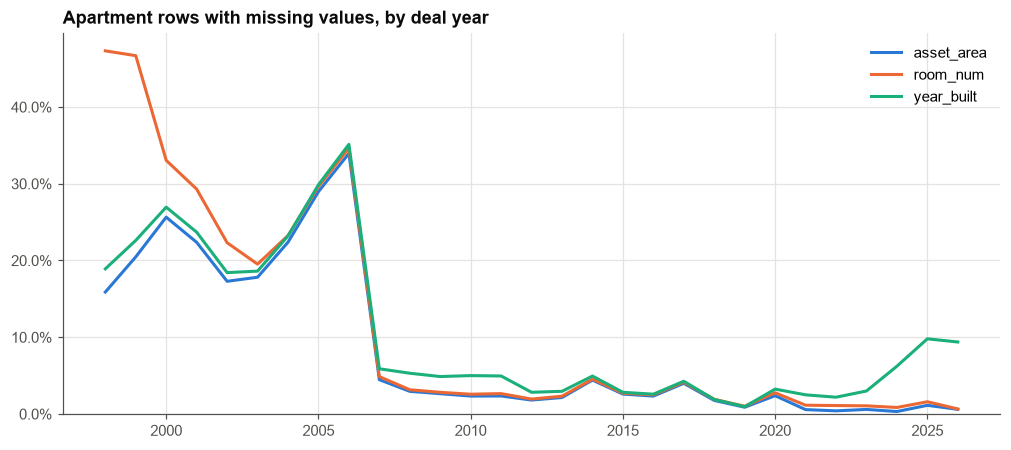

In [9]:
apt_all = df[df["deal_nature"].isin(APT_TYPES)]

miss = pd.DataFrame({"missing %": apt_all[["asset_area", "room_num", "year_built", "portion", "settlement"]].isna().mean() * 100})
print(f"Apartment-type rows: {len(apt_all):,}")
print(miss.round(1).to_string())

# Is "area missing" random? Compare the deals that have it with those that don't.
cmp = (apt_all.assign(area_missing=apt_all["asset_area"].isna())
       .groupby("area_missing")
       .agg(deals=("deal_amount", "size"), median_price=("deal_amount", "median"),
            median_year=("year", "median"), share_before_2003=("year", lambda y: (y < 2003).mean())))
print("\nDo apartments with a missing area differ from those with an area?")
print(cmp.round(2).to_string())

miss_year = apt_all.groupby("year")[["asset_area", "room_num", "year_built"]].apply(lambda d: d.isna().mean() * 100)
fig, ax = plt.subplots()
for col, color in zip(miss_year.columns, [C[0], C[1], C[2]]):
    ax.plot(miss_year.index, miss_year[col], color=color, label=col)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0)
ax.legend(frameon=False)
ax.set_title("Apartment rows with missing values, by deal year")
plt.show()

**Missingness is not random.** Apartments without an area have a much lower median price and come mostly from
earlier years (see the table and chart above). Dropping them therefore tilts the price sample toward newer, pricier
deals, and no imputation would fix that: the unknown values are exactly the ones we can't learn from.

**Decisions**
| field | decision | reason |
|---|---|---|
| `asset_area` | **drop** the row from price/m² analyses | it's the denominator of the target. Imputing it would manufacture the price/m² |
| `deal_amount` | no NaNs; implausible values are filtered (3.4) | |
| `settlement` | **drop** from city analyses | a handful of rows, can't be located |
| `portion` | **keep** partial shares and **normalise** the price (`deal_amount / portion`). **Drop** only rows where the share is unknown | partial deals are common and real (3.5). Without a known share the price can't be converted |
| `room_num` | **keep** the row, leave NaN | only the by-rooms chart needs it. Dropping would lose valid price data from every other chart |
| `year_built` | **keep** the row, leave NaN | same: only the building-age chart needs it |
| deal year | **keep** all years (1998 on) | the old flat label `ד. מגורים` (3.2) covers the early years, so they are not just new builds |

Rooms and build year are not imputed. A model-based fill (e.g. rooms from area) would be correlated with price by
construction and would bias the by-rooms and by-age comparisons.

### 3.4 Anomalies in apartment deals (row level)
First, the raw shape of price, area and price per m².

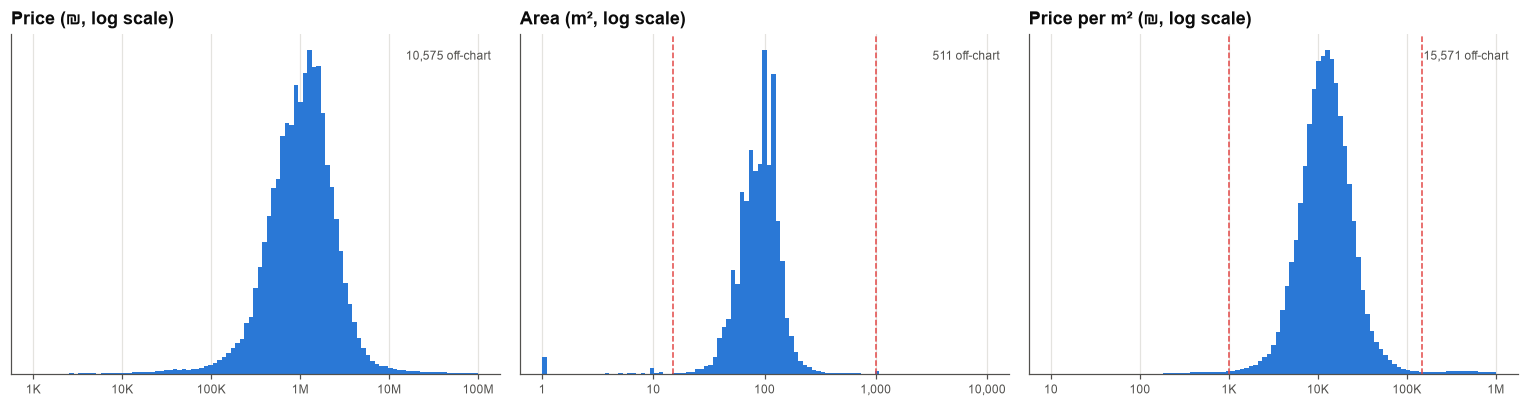

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
unit_price = apt_all["deal_amount"] / apt_all["portion"]            # price of the whole unit (see 3.5)
price_m2 = (unit_price / apt_all["asset_area"]).replace([np.inf, -np.inf], np.nan)
# (values, lower limit, upper limit, view range as powers of 10, tick labels, title)
panels = [
    (unit_price, None, None, (3, 8), ["1K", "10K", "100K", "1M", "10M", "100M"], "Price (₪, log scale)"),
    (apt_all["asset_area"], 15, 1_000, (0, 4), ["1", "10", "100", "1,000", "10,000"], "Area (m², log scale)"),
    (price_m2, 1_000, 150_000, (1, 6), ["10", "100", "1K", "10K", "100K", "1M"], "Price per m² (₪, log scale)"),
]
for ax, (x, lo, hi, (a, b), ticklabels, title) in zip(axes, panels):
    x = x.dropna()
    x = x[x > 0]
    ax.hist(np.log10(x), bins=np.linspace(a, b, 100), color=C[0])
    for limit in (lo, hi):
        if limit:
            ax.axvline(np.log10(limit), color=C[7], ls="--", lw=1)
    ax.set_xticks(range(a, b + 1), ticklabels, fontsize=8)
    ax.set_yticks([])
    ax.set_title(title)
    outside = ((x < 10**a) | (x > 10**b)).sum()
    ax.text(0.98, 0.95, f"{outside:,} off-chart", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=INK2)
plt.tight_layout(); plt.show()

Dashed lines mark the limits used below. The bulk of the distribution sits inside them. The tails mix real deals
(large penthouses, luxury flats) with errors (a 1 m² area, a symbolic ₪1,000 price, an extra zero in the area).

Instead of cutting at a fixed price or area, a deal is dropped only when it is **inconsistent or implausible**:
1. **Physically implausible size**: under 15 m² or over 1,000 m² cannot be a flat.
2. **Price and area disagree**: price per m² outside ₪1K-150K. A real large flat has a normal price per m². A typo does not.
3. **Local outlier**: price per m² far from its own city and year (robust z-score). A fixed cap can't do this, because
   ₪40K/m² is normal in Tel Aviv and an error in Dimona.

Real extreme deals (a big penthouse, a luxury flat) pass all three tests and are **kept**.

In [11]:
MIN_M2, MAX_M2 = 15, 1_000                      # physically plausible dwelling size
PPSQM_LO, PPSQM_HI = 1_000, 150_000             # price and area must agree

# `deal_amount` is what was paid for the share sold. Dividing by `portion` gives the price of the whole unit (3.5).
df["unit_price"] = df["deal_amount"] / df["portion"]
df["ppsqm"] = df["unit_price"] / df["asset_area"]

stages = [
    ("apartment property types (3.2)",       df["deal_nature"].isin(APT_TYPES)),
    ("share sold known (0 < portion <= 1)",  df["portion"].between(0, 1)),
    ("settlement known",                     df["settlement"].notna()),
    ("area known",                           df["asset_area"].notna()),
    (f"area {MIN_M2}-{MAX_M2:,} m²",         df["asset_area"].between(MIN_M2, MAX_M2)),
    (f"price/m² ₪{PPSQM_LO:,}-{PPSQM_HI:,}", df["ppsqm"].between(PPSQM_LO, PPSQM_HI)),
]
keep = pd.Series(True, index=df.index)
waterfall = []
for name, cond in stages:
    before = int(keep.sum())
    keep &= cond.fillna(False)
    waterfall.append({"step": name, "rows removed": before - int(keep.sum()), "rows left": int(keep.sum())})
    if name == "area known":
        cand_mask = keep.copy()      # every whole-unit apartment deal with a usable area, before the plausibility tests
apt = df[keep].copy()
pd.DataFrame(waterfall)

,step,rows removed,rows left
0,apartment property types (3.2),1266277,2577923
1,share sold known (0 < portion <= 1),27106,2550817
2,settlement known,777,2550040
3,area known,177198,2372842
4,"area 15-1,000 m²",25284,2347558
5,"price/m² ₪1,000-150,000",29126,2318432


Statistical outliers removed: 45,103 (1.95% of 2,318,432 apartment deals)


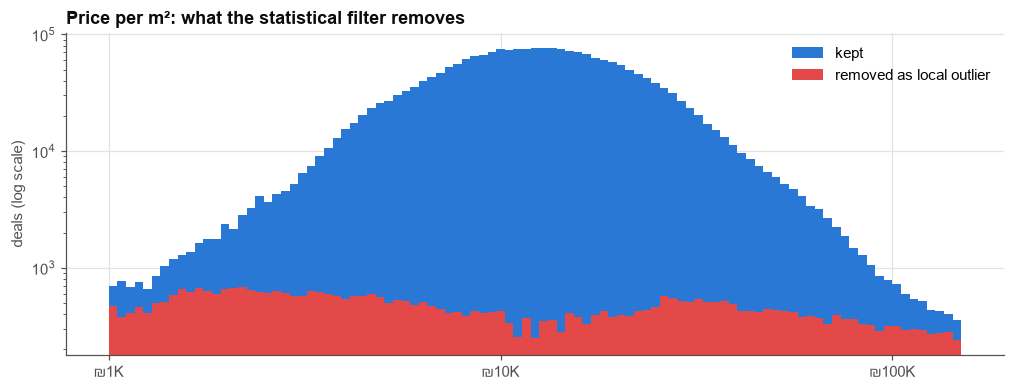

2,273,329 apartment deals kept (88% of apartment-type rows)


In [12]:
# Statistical filter: robust z-score (median/MAD) of log price per m² within each settlement-year.
# Only groups with >= 30 deals are judged; small groups don't have a reliable "local normal".
lp = np.log(apt["ppsqm"])
grp = [apt["settlement"], apt["year"]]
med = lp.groupby(grp).transform("median")
mad = (lp - med).abs().groupby(grp).transform("median").replace(0, np.nan)
size = lp.groupby(grp).transform("size")
z = 0.6745 * (lp - med) / mad
is_outlier = (size >= 30) & (z.abs() > 4)
print(f"Statistical outliers removed: {is_outlier.sum():,} ({is_outlier.mean():.2%} of {len(apt):,} apartment deals)")

fig, ax = plt.subplots(figsize=(11, 3.8))
bins = np.linspace(np.log10(1_000), np.log10(150_000), 100)
ax.hist(np.log10(apt["ppsqm"]), bins=bins, color=C[0], label="kept")
ax.hist(np.log10(apt.loc[is_outlier, "ppsqm"]), bins=bins, color=C[7], label="removed as local outlier")
ax.set_xticks([3, 4, 5]); ax.set_xticklabels(["₪1K", "₪10K", "₪100K"])
ax.set_yscale("log"); ax.legend(frameon=False)
ax.set_ylabel("deals (log scale)")
ax.set_title("Price per m²: what the statistical filter removes")
plt.show()

# Record why each candidate deal was dropped (empty = kept)
cand = df[cand_mask].copy()
cand["drop_reason"] = ""
cand.loc[~cand["asset_area"].between(MIN_M2, MAX_M2), "drop_reason"] = f"area outside {MIN_M2}-{MAX_M2:,} m²"
cand.loc[(cand["drop_reason"] == "") & ~cand["ppsqm"].between(PPSQM_LO, PPSQM_HI), "drop_reason"] = f"price/m² outside ₪{PPSQM_LO:,}-{PPSQM_HI:,}"
cand.loc[is_outlier[is_outlier].index, "drop_reason"] = "local price/m² outlier"
apt = cand[cand["drop_reason"] == ""].copy()
apt["age"] = apt["year"] - apt["year_built"]
print(f"{len(apt):,} apartment deals kept ({len(apt)/df['deal_nature'].isin(APT_TYPES).sum():.0%} of apartment-type rows)")

The removed deals (red) are spread across the whole price range, not just the tails. That is intended: a ₪10K/m² deal is
ordinary nationally but an anomaly in Tel Aviv, and the filter judges each deal against its own city and year.

### 3.5 Partial-share deals (`portion` < 1): separate frame, normalised price
About 1 in 5 apartment deals sells only a share of the flat (half, a third, a quarter...). These are real transactions, so they are
**kept**, but `deal_amount` is then the price of *the share*, not of the flat. `partial` holds them in a separate frame, and the
claim "the paid amount is for the share" is tested against whole-unit deals in the same city and year.

In [13]:
partial = cand[cand["portion"] < 1].copy()
partial["verdict"] = np.where(partial["drop_reason"] == "", "kept", "dropped")
partial["paid_ppsqm"] = partial["deal_amount"] / partial["asset_area"]          # price per m² as recorded
print(f"{len(partial):,} partial-share deals = {len(partial)/len(cand):.1%} of apartment candidates; "
      f"{(partial['verdict'] == 'kept').mean():.1%} survive the plausibility tests")

# Reference: median price per m² of whole-unit deals in the same settlement and year (>= 30 deals)
whole = cand[cand["portion"] == 1]
local = whole.groupby(["settlement", "year"])["ppsqm"].agg(["median", "size"]).query("size >= 30")["median"].rename("local_whole")
chk = partial.join(local, on=["settlement", "year"]).dropna(subset=["local_whole"]).copy()
chk["paid / whole"] = chk["paid_ppsqm"] / chk["local_whole"]
chk["normalised / whole"] = chk["ppsqm"] / chk["local_whole"]
chk["portion group"] = np.select(
    [chk["portion"].between(0.49, 0.51), chk["portion"].between(0.32, 0.34), chk["portion"].between(0.24, 0.26),
     chk["portion"] < 0.24, chk["portion"] > 0.51],
    ["1/2", "1/3", "1/4", "under 1/4", "over 1/2"], default="other")
order_ = ["1/2", "1/3", "1/4", "under 1/4", "over 1/2", "other"]
share_test = chk.groupby("portion group").agg(
    deals=("portion", "size"), expected_if_share=("portion", "median"),
    paid_over_whole=("paid / whole", "median"),
    normalised_over_whole=("normalised / whole", "median"),
    normalised_q25=("normalised / whole", lambda x: x.quantile(.25)),
    normalised_q75=("normalised / whole", lambda x: x.quantile(.75))).loc[order_]
display(share_test.round(2))
ref_ratio = (whole.join(local, on=["settlement", "year"]).dropna(subset=["local_whole"])
             .eval("ppsqm / local_whole").quantile([.25, .5, .75]))
print("Whole-unit deals vs their own city-year median (q25 / median / q75):", ref_ratio.round(2).tolist())

461,924 partial-share deals = 19.5% of apartment candidates; 90.3% survive the plausibility tests


,deals,expected_if_share,paid_over_whole,normalised_over_whole,normalised_q25,normalised_q75
portion group,,,,,,
1/2,179159,0.50,0.50,1.00,0.85,1.20
1/3,49956,0.33,0.33,0.99,0.83,1.18
1/4,33676,0.25,0.25,1.00,0.83,1.24
under 1/4,118051,0.10,0.14,1.10,0.86,2.01
over 1/2,42563,0.75,0.74,1.02,0.84,1.22
other,18990,0.38,0.39,1.06,0.88,1.32


Whole-unit deals vs their own city-year median (q25 / median / q75): [0.86, 1.0, 1.16]


**Reading the table.** If the paid amount were the price of the whole flat, `paid_over_whole` would be about 1. Instead it is
close to the share sold (0.50 for halves, 0.33 for thirds), so `deal_amount` is the price of the **share**. After dividing by
`portion`, `normalised_over_whole` is about 1.0, with a spread similar to whole-unit deals. The very small shares (under 1/4) are
noisier, because a small error in `portion` is magnified by the division.

So partial deals enter `apt` with `unit_price = deal_amount / portion`, and price per m² and every price chart in section 5 use
`unit_price`. They go through the same plausibility and outlier tests as whole-unit deals. Examples:

In [14]:
show_cols = ["portion group", "verdict", "drop_reason", "settlement", "deal_date", "deal_amount", "portion", "unit_price",
             "asset_area", "paid_ppsqm", "ppsqm", "local_whole", "gush", "chelka"]
ex = partial.join(chk[["portion group", "local_whole"]]).dropna(subset=["local_whole"])
examples = pd.concat([g.sample(min(4, len(g)), random_state=1)
                      for _, g in ex.groupby(["portion group", "verdict"])])[show_cols].reset_index(drop=True)
examples["deal_date"] = examples["deal_date"].dt.strftime("%Y-%m-%d")
examples

,portion group,verdict,drop_reason,settlement,deal_date,deal_amount,portion,unit_price,asset_area,paid_ppsqm,ppsqm,local_whole,gush,chelka
0,1/2,dropped,local price/m² outlier,נס ציונה,1998-08-16,"1,141,730.00",0.50,"2,283,460.00",124.00,"9,207.50","18,415.00","7,573.17",3850,167
1,1/2,dropped,local price/m² outlier,ראשון לציון,2008-03-20,"1,768,000.00",0.50,"3,536,000.00",125.00,"14,144.00","28,288.00","10,500.00",2704,55
2,1/2,dropped,"area outside 15-1,000 m²",אילת,2000-06-28,"288,556.00",0.50,"577,112.00",1.00,"288,556.00","577,112.00","6,296.64",40096,15
3,1/2,dropped,"area outside 15-1,000 m²",רחובות,2011-06-23,"719,974.00",0.50,"1,439,948.00",1.00,"719,974.00","1,439,948.00","12,455.33",5714,115
4,1/2,kept,,נתניה,2014-06-02,"317,500.00",0.50,"635,000.00",30.00,"10,583.33","21,166.67","13,888.89",8265,146
5,1/2,kept,,רחובות,2019-08-12,"870,000.00",0.50,"1,740,000.00",100.00,"8,700.00","17,400.00","17,934.78",3697,549
6,1/2,kept,,נס ציונה,2019-06-25,"770,000.00",0.50,"1,540,000.00",58.00,"13,275.86","26,551.72","20,795.45",3842,4
7,1/2,kept,,באר יעקב,2025-11-30,"1,004,557.00",0.50,"2,009,114.00",124.00,"8,101.27","16,202.53","16,259.18",4234,5
8,1/3,dropped,"area outside 15-1,000 m²",ראשון לציון,2010-04-06,"440,755.00",0.33,"1,323,588.57",1.00,"440,755.00","1,323,588.57","13,636.36",4246,21
9,1/3,dropped,local price/m² outlier,פתח תקווה,2012-02-07,"300,000.00",0.33,"900,900.89",28.00,"10,714.29","32,175.03","14,044.56",6328,101


### 3.6 Result
- `df`: all deals, deduplicated, with placeholders and impossible values nulled. Used for volume and property-type charts. **No rows dropped** beyond exact duplicates.
- `apt`: the clean apartment subset used for every price analysis in section 5. It keeps real extreme deals and partial-share deals (price normalised to `unit_price`).
- `partial`: all apartment deals with `portion` < 1, with a `verdict` (kept or dropped) and the reason.
- `cand`: every apartment candidate with its `drop_reason` (empty = kept).

In [15]:
summary = pd.DataFrame({
    "rows": [len(raw), len(df), df["deal_nature"].isin(APT_TYPES).sum(), len(apt)],
}, index=["raw file", "after removing duplicates (df)", "apartment-type rows", "clean apartment deals (apt)"])
summary["% of raw"] = summary["rows"] / len(raw) * 100
summary.round(1)

,rows,% of raw
raw file,3844200,100.00
after removing duplicates (df),3844200,100.00
apartment-type rows,2577923,67.10
clean apartment deals (apt),2273329,59.10


## 4. Deal volume

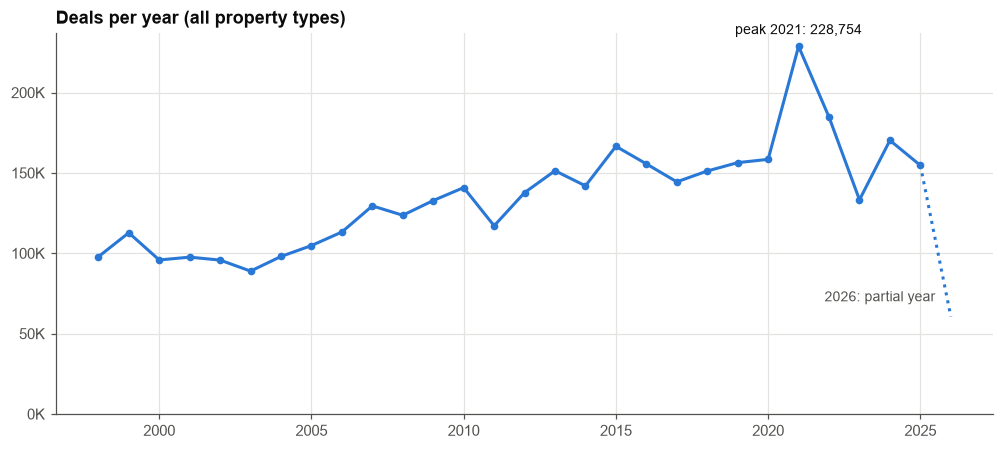

In [16]:
yearly = df.groupby("year").size()
full_years = yearly.loc[:2025]          # 2026 is a partial year
fig, ax = plt.subplots()
ax.plot(full_years.index, full_years.values, marker="o", markersize=4)
ax.plot([2025, 2026], yearly.loc[[2025, 2026]].values, ls=":", color=C[0])
ax.annotate("2026: partial year", (2026, yearly.loc[2026]), xytext=(-10, 10),
            textcoords="offset points", ha="right", color=INK2, fontsize=9)
peak = full_years.idxmax()
ax.annotate(f"peak {peak}: {full_years.max():,}", (peak, full_years.max()), xytext=(0, 8),
            textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0)
ax.set_title("Deals per year (all property types)")
plt.show()

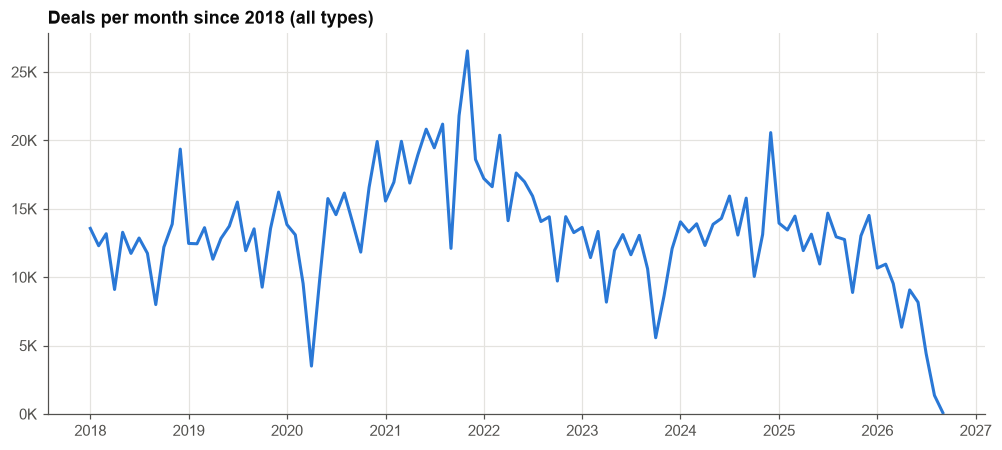

In [17]:
monthly = df[df["deal_date"] >= "2018-01-01"].groupby("month").size()
fig, ax = plt.subplots()
ax.plot(monthly.index.to_timestamp(), monthly.values)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0)
ax.set_title("Deals per month since 2018 (all types)")
plt.show()

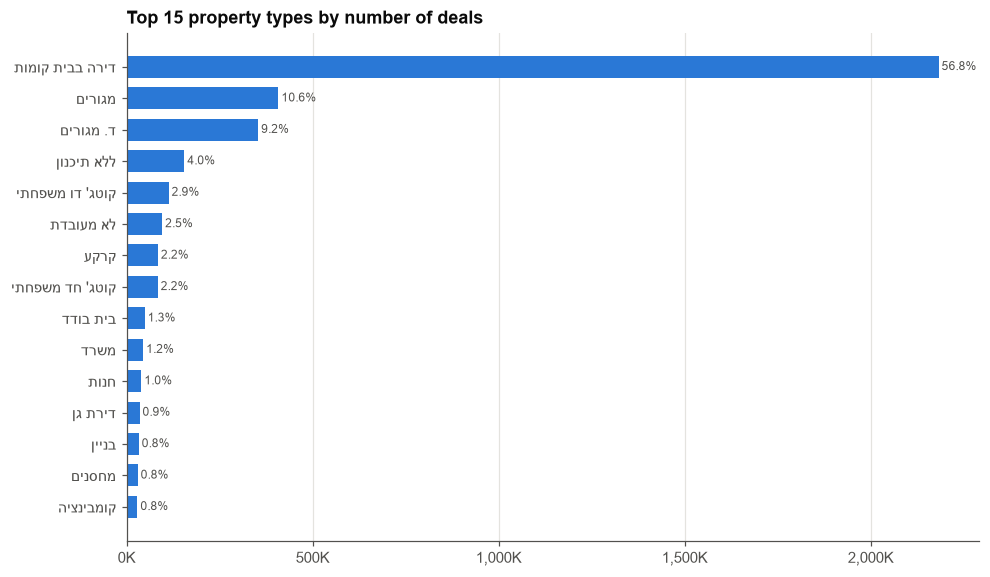

47 types in total; the top 15 cover 97.0% of deals


In [18]:
types = df["deal_nature"].value_counts()
top = types.head(15)[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([heb(t) for t in top.index], top.values, color=C[0], height=0.7)
for y, v in enumerate(top.values):
    ax.text(v, y, f" {v/len(df):.1%}", va="center", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
ax.set_title("Top 15 property types by number of deals")
plt.show()
print(f"{types.size} types in total; the top 15 cover {types.head(15).sum()/len(df):.1%} of deals")

## 5. Residential apartments

Price analysis (`unit_price` = price of the whole flat) uses the clean subset `apt` built in section 3 (apartment types, whole units and partial shares at their whole-unit price, physically plausible size,
consistent price per m², no local outliers). `RECENT` is the same subset restricted to 2024 on.

Prices are **nominal** (not adjusted for inflation).

In [19]:
RECENT = apt[apt["year"] >= 2024]
print(f"{len(apt):,} apartment deals, {len(RECENT):,} since 2024")

2,273,329 apartment deals, 253,175 since 2024


In [20]:
by_year = apt.groupby("year").agg(deals=("ppsqm", "size"),
                                  median_price=("unit_price", "median"),
                                  median_ppsqm=("ppsqm", "median"),
                                  median_area=("asset_area", "median"))
by_year["ppsqm_yoy"] = by_year["median_ppsqm"].pct_change()
by_year

,deals,median_price,median_ppsqm,median_area,ppsqm_yoy
year,,,,,
1998,54416,"547,650.00","6,726.39",81.00,NaN
1999,59987,"572,500.00","7,080.03",82.00,0.05
2000,47895,"557,415.00","7,077.12",80.00,-0.00
2001,53060,"540,000.00","6,652.59",84.00,-0.06
2002,54944,"642,870.00","7,605.76",85.00,0.14
2003,49879,"607,047.00","7,329.42",83.00,-0.04
2004,48917,"620,000.00","7,740.30",80.00,0.06
2005,47074,"632,995.50","7,927.43",80.00,0.02
2006,47032,"664,439.00","8,100.00",82.00,0.02


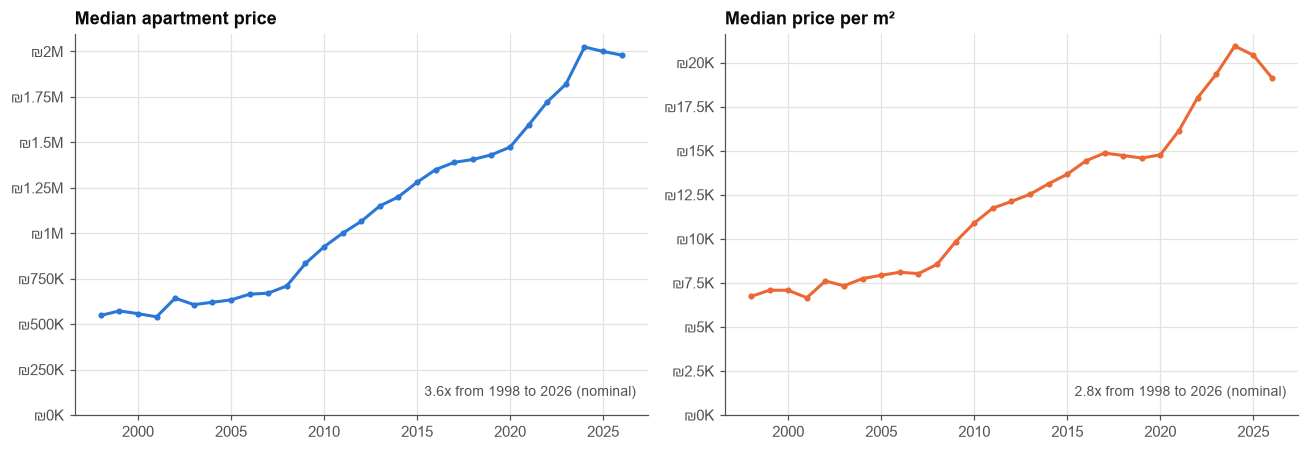

In [21]:
# Two measures with different scales -> two charts, not a dual axis
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, title, color in [
    (axes[0], "median_price", "Median apartment price", C[0]),
    (axes[1], "median_ppsqm", "Median price per m²", C[1]),
]:
    s = by_year[col]
    ax.plot(s.index, s.values, color=color, marker="o", markersize=3)
    ax.yaxis.set_major_formatter(shekels)
    ax.set_ylim(0)
    ax.set_title(title)
    first, last = s.index.min(), s.index.max()
    ax.text(0.98, 0.05, f"{s[last]/s[first]:.1f}x from {first} to {last} (nominal)", transform=ax.transAxes,
            ha="right", fontsize=9, color=INK2)
plt.tight_layout(); plt.show()

### Cities

89 localities with at least 300 apartment deals since 2024 (and at least 20% whole-unit deals)


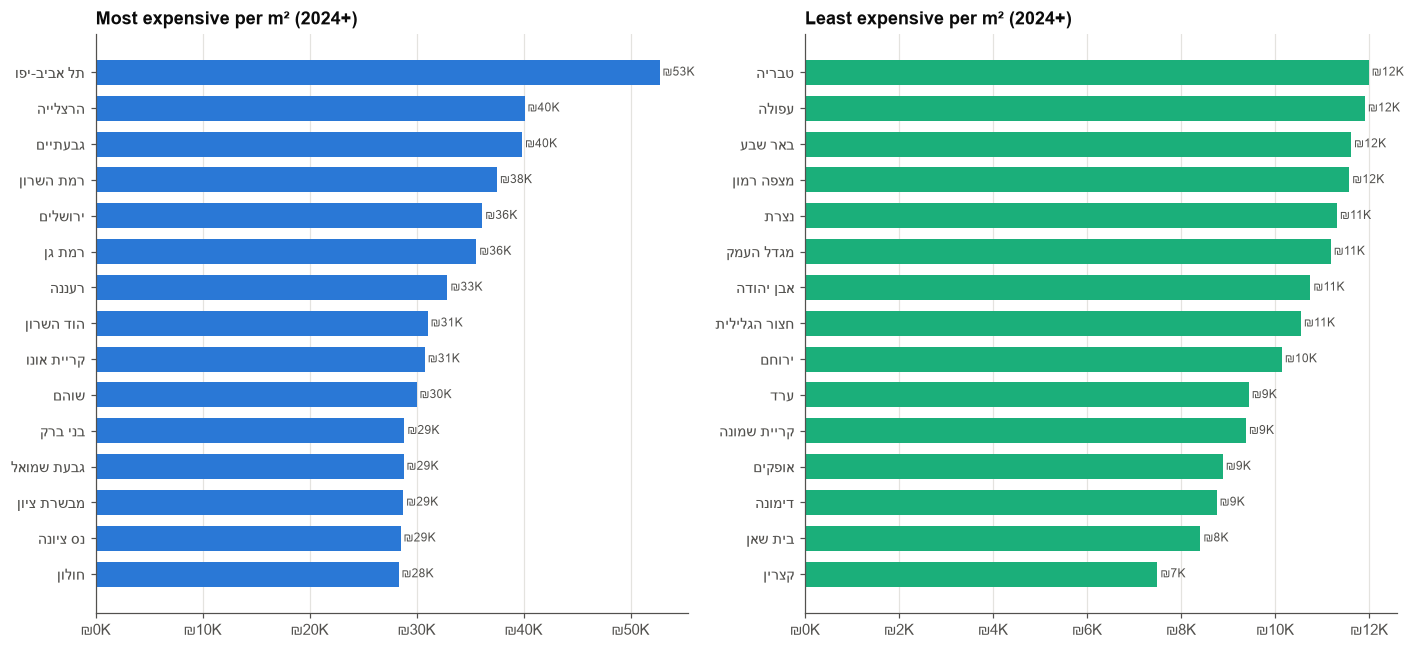

In [22]:
RECENT = apt[apt["year"] >= 2024]
city = (RECENT.groupby("settlement")
        .agg(deals=("ppsqm", "size"), median_price=("unit_price", "median"),
             median_ppsqm=("ppsqm", "median"), median_area=("asset_area", "median"),
             whole_share=("portion", lambda x: (x == 1).mean()))
        # a locality where almost every deal is a partial share (e.g. cooperative settlements) has no reliable whole-flat price
        .query("deals >= 300 and whole_share >= 0.2").sort_values("median_ppsqm", ascending=False))
print(f"{len(city)} localities with at least 300 apartment deals since 2024 (and at least 20% whole-unit deals)")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, part, title, color in [
    (axes[0], city.head(15), "Most expensive per m² (2024+)", C[0]),
    (axes[1], city.tail(15), "Least expensive per m² (2024+)", C[2]),
]:
    part = part[::-1]
    ax.barh([heb(s) for s in part.index], part["median_ppsqm"], color=color, height=0.7)
    for y, v in enumerate(part["median_ppsqm"]):
        ax.text(v, y, f" ₪{v/1e3:,.0f}K", va="center", fontsize=8, color=INK2)
    ax.xaxis.set_major_formatter(shekels)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

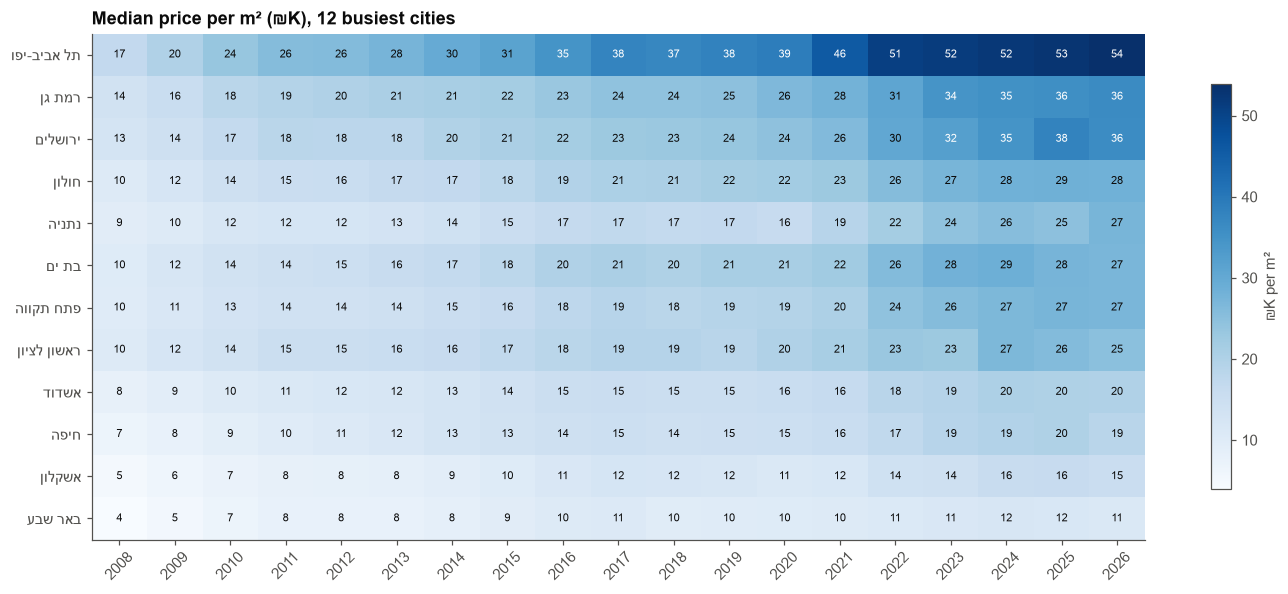

In [23]:
top_cities = apt["settlement"].value_counts().head(12).index
heat = (apt[apt["settlement"].isin(top_cities) & (apt["year"] >= 2008)]
        .pivot_table(index="settlement", columns="year", values="ppsqm", aggfunc="median"))
heat = heat.loc[heat[heat.columns.max()].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(heat.values / 1e3, aspect="auto", cmap="Blues")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=45)
ax.set_yticks(range(heat.shape[0]), [heb(s) for s in heat.index])
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j] / 1e3
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if im.norm(v) > 0.55 else INK)
fig.colorbar(im, ax=ax, label="₪K per m²", shrink=0.8)
ax.set_title("Median price per m² (₪K), 12 busiest cities")
plt.tight_layout(); plt.show()

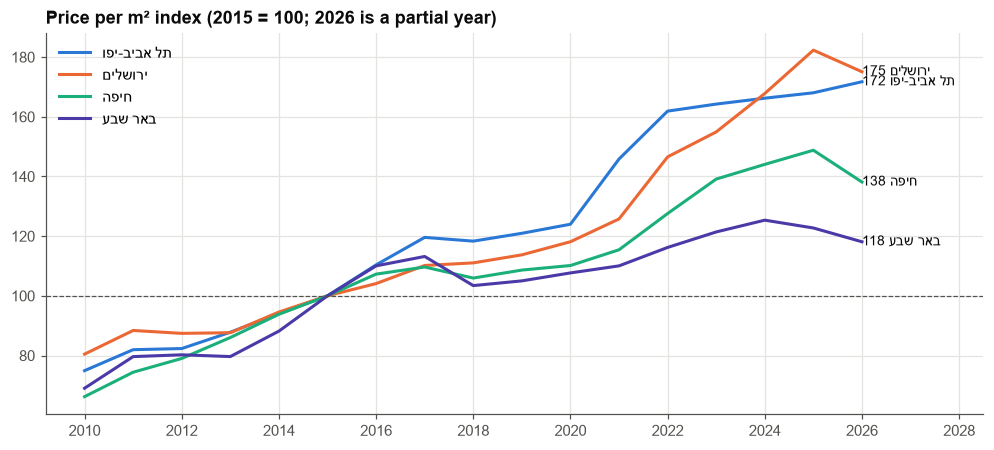

In [24]:
# Growth indexed to 2015 = 100, so cities with different price levels compare on one axis
FOCUS = {"תל אביב-יפו": C[0], "ירושלים": C[1], "חיפה": C[2], "באר שבע": C[6]}
idx = (apt[apt["settlement"].isin(FOCUS) & (apt["year"] >= 2010)]
       .pivot_table(index="year", columns="settlement", values="ppsqm", aggfunc="median"))
idx = idx / idx.loc[2015] * 100

fig, ax = plt.subplots()
for city_name, color in FOCUS.items():
    s = idx[city_name]
    ax.plot(s.index, s.values, color=color, label=heb(city_name))
    ax.annotate(f" {heb(city_name)} {s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]),
                va="center", fontsize=9, color=INK)
ax.axhline(100, color=INK2, lw=0.8, ls="--")
ax.set_xlim(right=idx.index.max() + 2.5)
ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
ax.legend(frameon=False, loc="upper left")
ax.set_title("Price per m² index (2015 = 100; 2026 is a partial year)")
plt.show()

### Rooms and building age

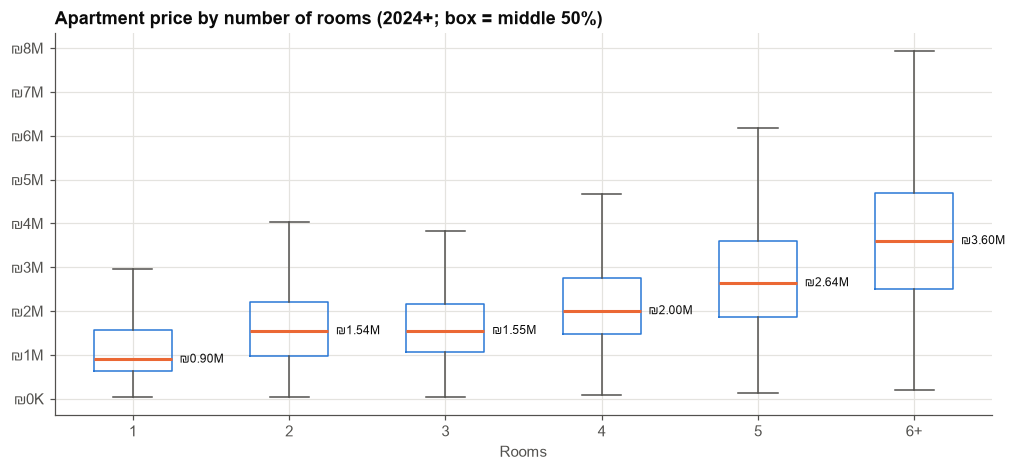

,size,median
rooms,,
1,1082,"896,551.00"
2,15456,"1,545,000.00"
3,71648,"1,550,000.00"
4,92448,"2,002,002.23"
5,57937,"2,640,000.00"
6+,13891,"3,600,000.00"


In [25]:
r = RECENT.dropna(subset=["room_num"]).copy()
r["rooms"] = r["room_num"].clip(upper=6).round().astype(int).map(lambda x: "6+" if x >= 6 else str(x))
order = ["1", "2", "3", "4", "5", "6+"]
groups = [r.loc[r["rooms"] == k, "unit_price"] for k in order]

fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=order, showfliers=False, widths=0.5,
           medianprops=dict(color=C[1], lw=2), boxprops=dict(color=C[0]),
           whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
for i, g in enumerate(groups, 1):
    ax.text(i + 0.3, g.median(), f"₪{g.median()/1e6:.2f}M", va="center", fontsize=8, color=INK)
ax.yaxis.set_major_formatter(shekels)
ax.set_xlabel("Rooms")
ax.set_title("Apartment price by number of rooms (2024+; box = middle 50%)")
plt.show()
r.groupby("rooms")["unit_price"].agg(["size", "median"]).loc[order]

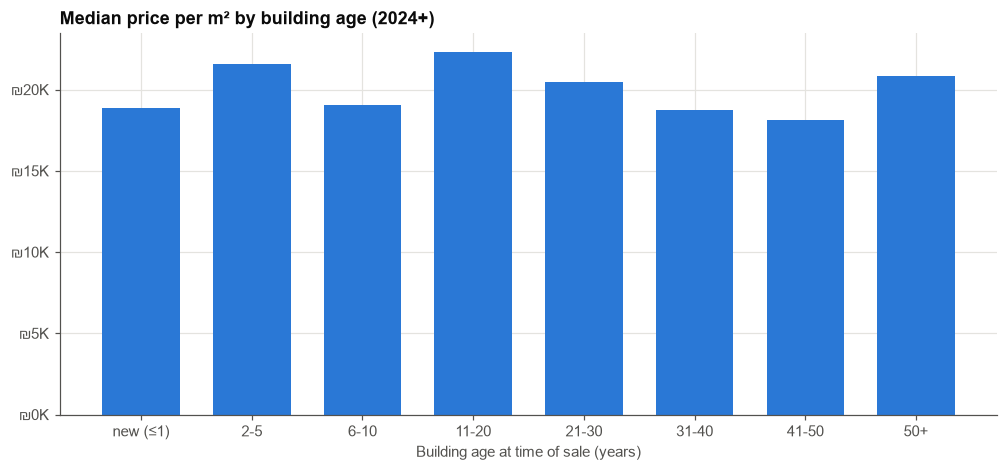

,deals,median_ppsqm,median_area
age_bin,,,
new (≤1),76393,"18,877.55",108.00
2-5,27047,"21,600.00",117.00
6-10,20964,"19,056.34",120.00
11-20,14842,"22,340.43",118.00
21-30,18865,"20,472.44",101.00
31-40,13832,"18,750.00",92.00
41-50,8698,"18,155.05",83.00
50+,54058,"20,851.06",70.00


In [26]:
a = RECENT.dropna(subset=["age"]).copy()
bins = [-np.inf, 1, 5, 10, 20, 30, 40, 50, np.inf]
labels = ["new (≤1)", "2-5", "6-10", "11-20", "21-30", "31-40", "41-50", "50+"]
a["age_bin"] = pd.cut(a["age"], bins=bins, labels=labels)
age_tbl = a.groupby("age_bin", observed=True).agg(deals=("ppsqm", "size"),
                                                  median_ppsqm=("ppsqm", "median"),
                                                  median_area=("asset_area", "median"))
fig, ax = plt.subplots()
ax.bar(age_tbl.index.astype(str), age_tbl["median_ppsqm"], color=C[0], width=0.7)
ax.yaxis.set_major_formatter(shekels)
ax.set_xlabel("Building age at time of sale (years)")
ax.set_title("Median price per m² by building age (2024+)")
plt.show()
age_tbl

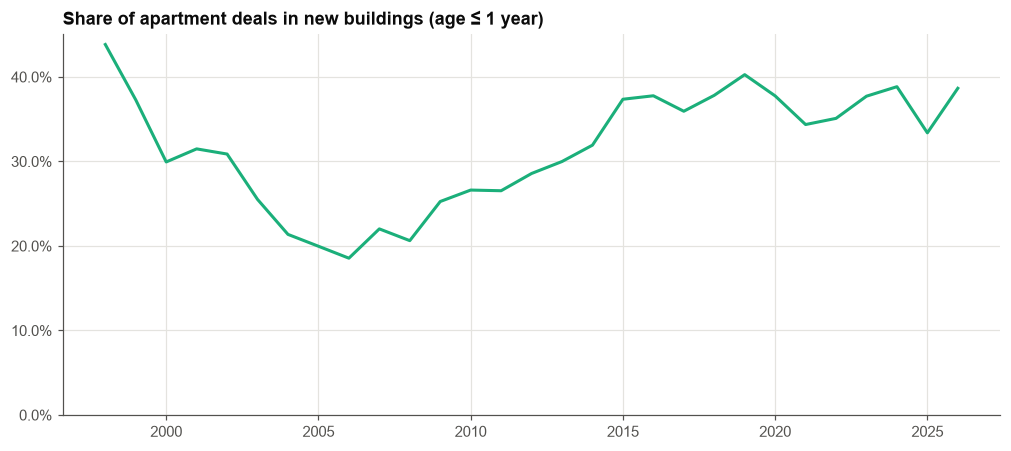

In [27]:
# Share of deals in new buildings (pre-sale or up to 1 year old) per year
# Sanity check on including the early years: the new-build share should not jump at the old/new label switch (2003)
apt_all = df[df["deal_nature"].isin(APT_TYPES) & (df["portion"] == 1)].copy()
apt_all["age"] = apt_all["year"] - apt_all["year_built"]
new_share = apt_all.dropna(subset=["age"]).assign(new=lambda d: d["age"] <= 1).groupby("year")["new"].mean()
fig, ax = plt.subplots()
ax.plot(new_share.index, new_share.values * 100, color=C[2])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0)
ax.set_title("Share of apartment deals in new buildings (age ≤ 1 year)")
plt.show()

## Summary

- **Volume:** about 3.84M deal records from 1998 to Sep 2026, with no exact duplicates. Deals peaked in **2021 (229K)**,
  then fell sharply to 133K in 2023 (rate hikes) before partly recovering in 2024.
- **Mix:** apartments in buildings (דירה בבית קומות) make up 57% of all deals. The top 15 of 47 property types cover 97%.
- **Cleaning:** 0 is a placeholder for unknown, and impossible values (build year 9999, 99 rooms) are nulled, but the rows are kept.
  Apartments are the 4 flat labels (the old `ד. מגורים` label covers 1998 to 2003). Partial-share deals (about 1 in 5) are kept and
  their price is divided by the share sold. Price analyses drop rows without area or share and
  drop deals that are physically implausible, whose price and area disagree, or that are local outliers. Extreme but
  consistent deals (big penthouses, luxury flats) are kept. This leaves 1.85M clean apartment deals (72% of apartment-type rows).
- **Missing values:** 0 is used as a placeholder. Build year is missing in 28% of rows, area in 21%, rooms in 34%.
  Outliers are extreme (areas up to 10⁹ m², prices up to ₪9B), so medians and filtered subsets are used throughout.
- **Prices (nominal, apartments):** the median price went from ₪0.54M (1998) to about ₪2.02M (2024), and price per m²
  from about ₪6.7K to ₪20.9K. Prices were flat from 2017 to 2020, rose fast from 2021 to 2024, and slipped slightly
  in 2025 to 2026.
- **Cities (2024+):** Tel Aviv-Yafo is in a league of its own at about ₪53K/m². Next are Herzliya, Givatayim,
  Ramat HaSharon, Jerusalem and Ramat Gan (₪36K to ₪40K). The periphery (Katzrin, Beit She'an, Ofakim, Dimona) sits at
  ₪7.5K to ₪9.5K/m², a 6 to 7x gap.
- **Growth since 2015:** Tel Aviv +72% and Jerusalem +75%, while Haifa (+38%) and Be'er Sheva (+18%) grew much less.
- **Rooms:** 3-room apartments have a median price close to 2-room ones (about ₪1.5M). After that, each extra room
  adds about ₪0.5M to ₪1M.
- **Building age:** price per m² barely changes with age. Location matters far more than whether the building is new.

*Caveats:* prices are not inflation-adjusted, 2026 is a partial year, and medians mix locations, so city-level
changes partly reflect which neighborhoods traded in a given year.